# 综合案例：曲线拟合与标定

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

现在把建模、初始化、加权求解、残差诊断和不确定性放进同一个流程。任务是从一个衰减响应估计幅值$a$、衰减速率$k$和背景值$c$。

## 在拟合前固定实验规则

数据来自仓库中的decay-calibration.csv，明确为合成数据。时间单位为秒，响应使用任意一致单位，每行给出已知噪声标准差。固定留出每五行中的第一行，其余用于拟合；留出数据不参与初值和参数选择。

模型为$f(t)=a e^{-kt}+c$，采用白化残差$(f-y)/\sigma$。$a$和$k$应为非负。初值不读取仿真真参数，而是在一组候选$k$上，对$a,c$做线性最小二乘，并选择训练误差最小的一组。

In [2]:
data=np.genfromtxt(root/'data/decay-calibration.csv',delimiter=',',names=True)
t,y,sigma=data['time_s'],data['response'],data['noise_sigma']
train=np.arange(len(t))%5!=0
tt,yy,ss=t[train],y[train],sigma[train]
candidates=[]
for k in np.linspace(.1,1.5,50):
    A=np.column_stack([np.exp(-k*tt),np.ones_like(tt)])
    ac=np.linalg.lstsq(A/ss[:,None],yy/ss,rcond=None)[0]
    if ac[0]>=0:
        cost=np.sum(((A@ac-yy)/ss)**2)
        candidates.append((cost,np.array([ac[0],k,ac[1]])))
initial=min(candidates,key=lambda z:z[0])[1]
initial[2]=max(0.,initial[2])
def model(p,t):
    return p[0]*np.exp(-p[1]*t)+p[2]
def residual(p):
    return (model(p,tt)-yy)/ss
def jac(p):
    e=np.exp(-p[1]*tt)
    return np.column_stack([e,-p[0]*tt*e,np.ones_like(tt)])/ss[:,None]
fit=least_squares(residual,initial,jac=jac,bounds=(0,np.inf),x_scale=[3,1,.3])
print('data-derived initial:',initial,'fit:',fit.x,'status:',fit.message)
print('training normalized RMSE:',np.sqrt(np.mean(residual(fit.x)**2)))
heldout=(model(fit.x,t[~train])-y[~train])/sigma[~train]
print('held-out normalized RMSE:',np.sqrt(np.mean(heldout**2)))
assert fit.success and np.all(np.isfinite(fit.x))

data-derived initial: [2.78596 0.67143 0.2823 ] fit: [2.79075 0.66143 0.26947] status: `ftol` termination condition is satisfied.
training normalized RMSE: 0.8496890299942883
held-out normalized RMSE: 1.07904696484996


## 可辨识性和局部不确定性

白化雅可比的奇异值跨度可以提示局部弱方向。这里噪声尺度是已知的，先用局部线性化估计$C_x\approx(J^TJ)^{-1}$，不再额外乘训练残差方差。若约束处于活动边界或模型明显非线性，这个正态近似会失真。

对新时间$t$，模型均值的一阶方差为$j(t)C_xj(t)^T$。这描述平均响应的不确定性；未来一次带噪声观测的预测方差还要加观测噪声方差。两种区间不可混为一谈。

Jacobian singular values: [243.55618  57.36661  29.09522]
approximate parameter standard errors: [0.02382 0.01723 0.02525]


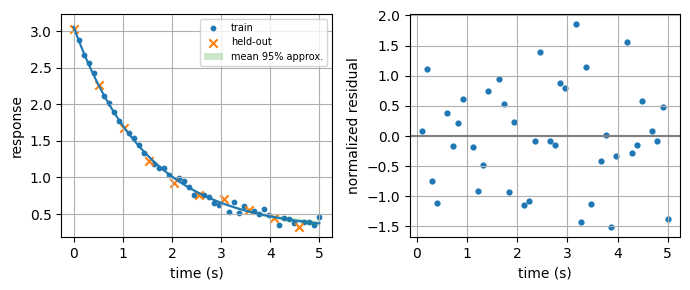

In [3]:
J=jac(fit.x)
_,s,Vt=np.linalg.svd(J,full_matrices=False)
cov=(Vt.T/(s*s))@Vt
print('Jacobian singular values:',s)
print('approximate parameter standard errors:',np.sqrt(np.diag(cov)))
grid=np.linspace(0,5,160);e=np.exp(-fit.x[1]*grid)
Jmean=np.column_stack([e,-fit.x[0]*grid*e,np.ones_like(grid)])
se=np.sqrt(np.einsum('ij,jk,ik->i',Jmean,cov,Jmean))
prediction=model(fit.x,grid)
fig,ax=plt.subplots(1,2,figsize=(7,3))
ax[0].scatter(tt,yy,s=10,label='train')
ax[0].scatter(t[~train],y[~train],marker='x',label='held-out')
ax[0].plot(grid,prediction)
ax[0].fill_between(grid,prediction-1.96*se,prediction+1.96*se,alpha=.25,label='mean 95% approx.')
ax[0].set(xlabel='time (s)',ylabel='response');ax[0].legend(fontsize=7)
ax[1].scatter(tt,residual(fit.x),s=12)
ax[1].axhline(0,color='gray');ax[1].set(xlabel='time (s)',ylabel='normalized residual')
plt.tight_layout();plt.show()

本例知道真模型，仍然不能要求每次仿真都把参数估到真值或让95%区间覆盖真值。概率陈述描述重复实验，不是一次实验的确定承诺。

## 将结果写成可以复查的结论

报告应包含模型、参数单位、数据筛选和划分、噪声/权重来源、求解方法、初值和边界、停止原因、训练/留出残差及不确定性假设。仅报告三个参数和一个“成功”不够。

## 练习与解答

练习：只保留很早的时间点，$a$和$c$是否容易分开？解答：不容易；当$kt$很小时，$a e^{-kt}+c\approx(a+c)-ak t$，数据主要约束$a+c$与$ak$两个组合。增加较晚的采样可提供背景信息。

练习：用同一批留出数据反复选择模型阶数后，还能把它称为最终独立评估吗？解答：不能；它已经参与模型选择，需要新的测试数据或嵌套验证。

练习：若残差随时间有系统曲率，扩大参数误差条能否解决？解答：不能；应先怀疑模型缺失、时间响应或噪声假设，协方差公式不能修复系统偏差。